# Notebook 2: Ghana Rainfall Variability Analysis (2000–2024)

**Objective:** Analyze monthly and annual rainfall patterns across Ghana from 2000 to 2024 using validated CHIRPS precipitation data.

**Research focus:** Quantify rainfall variability and long-term trends as a first step toward investigating potential relationships between rainfall, vegetation dynamics, and forage conditions.

**Data source:** CHIRPS monthly precipitation dataset, processed and validated in Notebook 1.

**Methodological note:** Rainfall patterns alone do not directly measure vegetation biomass, forage availability, or grazing pressure.

In [1]:
# Load validated Ghana rainfall data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "ghana_chirps_monthly_validated_2000_2024.csv"

rainfall_df = pd.read_csv(file_path, parse_dates=["time"])

print("Dataset shape:", rainfall_df.shape)
print("Columns:", rainfall_df.columns.tolist())
print("Date range:", rainfall_df["time"].min(), "to", rainfall_df["time"].max())
print("Unique months:", rainfall_df["time"].nunique())
print("Unique grid cells:",
      rainfall_df[["latitude", "longitude"]].drop_duplicates().shape[0])
print("Missing precipitation values:", rainfall_df["precip"].isna().sum())

print("\nFirst five rows:")
display(rainfall_df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'ghana_chirps_monthly_validated_2000_2024.csv'

In [2]:
# Check uploaded files
import os

print(os.listdir("/content"))

['.config', 'ghana_chirps_monthly_validated_2000_2024.csv', 'sample_data']


In [3]:
# Load and check the validated rainfall dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "/content/ghana_chirps_monthly_validated_2000_2024.csv"

rainfall_df = pd.read_csv(file_path, parse_dates=["time"])

print("Dataset shape:", rainfall_df.shape)
print("Date range:", rainfall_df["time"].min(), "to", rainfall_df["time"].max())
print("Unique months:", rainfall_df["time"].nunique())
print(
    "Unique grid cells:",
    rainfall_df[["latitude", "longitude"]].drop_duplicates().shape[0]
)
print("Missing precipitation values:", rainfall_df["precip"].isna().sum())

display(rainfall_df.head())

Dataset shape: (2367000, 4)
Date range: 2000-01-01 00:00:00+00:00 to 2024-12-01 00:00:00+00:00
Unique months: 300
Unique grid cells: 7890
Missing precipitation values: 0


,time,latitude,longitude,precip
0,2000-01-01 00:00:00+00:00,4.774998,-2.125,20.348320
1,2000-02-01 00:00:00+00:00,4.774998,-2.125,15.975458
2,2000-03-01 00:00:00+00:00,4.774998,-2.125,128.625600
3,2000-04-01 00:00:00+00:00,4.774998,-2.125,140.442250
4,2000-05-01 00:00:00+00:00,4.774998,-2.125,310.363650


Step 4: Calculate monthly rainfall statistics

In [4]:
# Calculate national monthly rainfall statistics
monthly_rainfall = (
    rainfall_df.groupby("time")["precip"]
    .mean()
    .reset_index(name="mean_precip_mm")
)

print("Monthly dataset shape:", monthly_rainfall.shape)
print("\nFirst 12 months:")
display(monthly_rainfall.head(12))

print("\nSummary statistics:")
display(monthly_rainfall["mean_precip_mm"].describe())

Monthly dataset shape: (300, 2)

First 12 months:


,time,mean_precip_mm
0,2000-01-01 00:00:00+00:00,14.043268
1,2000-02-01 00:00:00+00:00,10.695453
2,2000-03-01 00:00:00+00:00,57.256180
3,2000-04-01 00:00:00+00:00,109.879719
4,2000-05-01 00:00:00+00:00,149.658752
5,2000-06-01 00:00:00+00:00,214.182439
6,2000-07-01 00:00:00+00:00,124.966133
7,2000-08-01 00:00:00+00:00,130.354536
8,2000-09-01 00:00:00+00:00,156.577979
9,2000-10-01 00:00:00+00:00,118.400099



Summary statistics:


,mean_precip_mm
count,300.000000
mean,100.372179
std,66.559932
min,3.696005
25%,36.498641
50%,106.759233
75%,151.146009
max,277.445126


Step 5: Calculate annual rainfall estimates

In [5]:
# Calculate annual rainfall estimates from monthly grid-cell averages
monthly_rainfall["year"] = monthly_rainfall["time"].dt.year

annual_rainfall = (
    monthly_rainfall.groupby("year")["mean_precip_mm"]
    .sum()
    .reset_index(name="annual_rainfall_mm")
)

print("Number of years:", annual_rainfall.shape[0])
print("\nAnnual rainfall estimates:")
display(annual_rainfall)

print("\nSummary statistics:")
display(annual_rainfall["annual_rainfall_mm"].describe())

Number of years: 25

Annual rainfall estimates:


,year,annual_rainfall_mm
0,2000,1126.608681
1,2001,1043.306209
2,2002,1231.959347
3,2003,1271.682950
4,2004,1164.307682
5,2005,1132.839138
6,2006,1180.650980
7,2007,1393.724140
8,2008,1342.660911
9,2009,1287.013235



Summary statistics:


,annual_rainfall_mm
count,25.000000
mean,1204.466150
std,125.375656
min,893.536427
25%,1126.608681
50%,1200.816430
75%,1316.722776
max,1393.724140


Step 6: Visualize annual rainfall

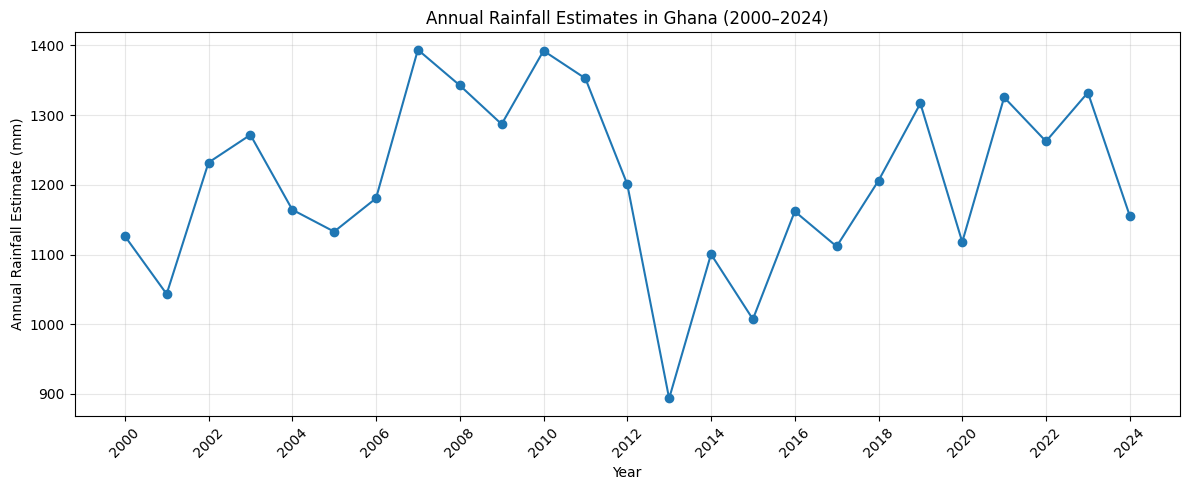

In [6]:
# Plot annual rainfall estimates from 2000 to 2024
plt.figure(figsize=(12, 5))

plt.plot(
    annual_rainfall["year"],
    annual_rainfall["annual_rainfall_mm"],
    marker="o"
)

plt.title("Annual Rainfall Estimates in Ghana (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Annual Rainfall Estimate (mm)")
plt.xticks(range(2000, 2025, 2), rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Step 7: Test the long-term rainfall trend

In [7]:
# Test the linear trend in annual rainfall estimates
from scipy.stats import linregress

trend = linregress(
    annual_rainfall["year"],
    annual_rainfall["annual_rainfall_mm"]
)

print(f"Slope: {trend.slope:.3f} mm/year")
print(f"Intercept: {trend.intercept:.3f}")
print(f"R-squared: {trend.rvalue**2:.4f}")
print(f"P-value: {trend.pvalue:.4f}")
print(f"Correlation coefficient: {trend.rvalue:.4f}")

Slope: 1.053 mm/year
Intercept: -913.489
R-squared: 0.0038
P-value: 0.7692
Correlation coefficient: 0.0618


Step 7: Test the long-term rainfall trend


In [8]:
# Test the linear trend in annual rainfall estimates
from scipy.stats import linregress

trend = linregress(
    annual_rainfall["year"],
    annual_rainfall["annual_rainfall_mm"]
)

print(f"Slope: {trend.slope:.3f} mm/year")
print(f"Intercept: {trend.intercept:.3f}")
print(f"R-squared: {trend.rvalue**2:.4f}")
print(f"P-value: {trend.pvalue:.4f}")
print(f"Correlation coefficient: {trend.rvalue:.4f}")

Slope: 1.053 mm/year
Intercept: -913.489
R-squared: 0.0038
P-value: 0.7692
Correlation coefficient: 0.0618


Step 8: Add the trend line to your chart

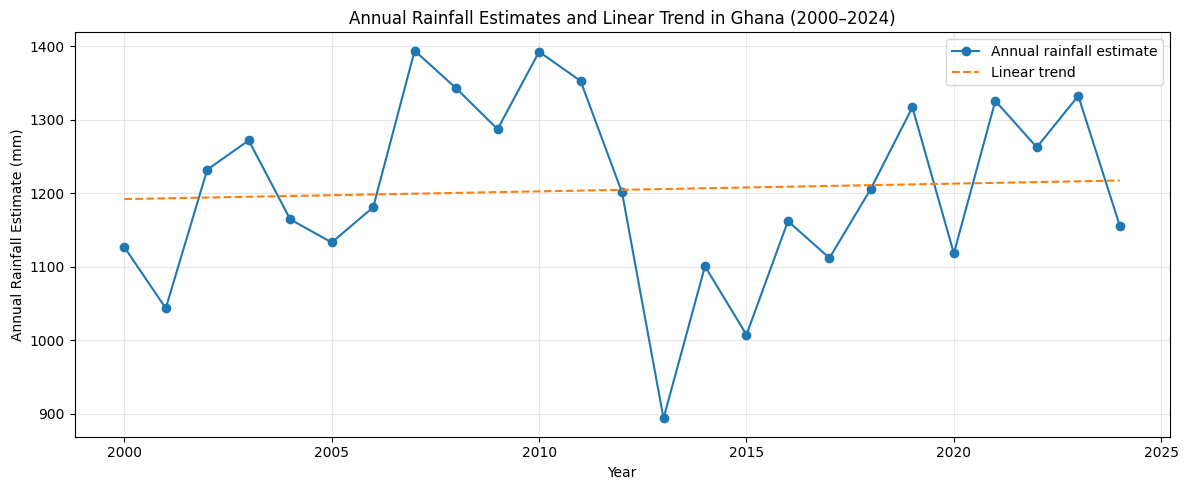

In [9]:
# Plot annual rainfall estimates with the fitted linear trend
from scipy.stats import linregress
import matplotlib.pyplot as plt

trend = linregress(
    annual_rainfall["year"],
    annual_rainfall["annual_rainfall_mm"]
)

plt.figure(figsize=(12, 5))

plt.plot(
    annual_rainfall["year"],
    annual_rainfall["annual_rainfall_mm"],
    marker="o",
    label="Annual rainfall estimate"
)

plt.plot(
    annual_rainfall["year"],
    trend.intercept + trend.slope * annual_rainfall["year"],
    linestyle="--",
    label="Linear trend"
)

plt.title("Annual Rainfall Estimates and Linear Trend in Ghana (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Annual Rainfall Estimate (mm)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Step 9: Calculate rainfall variability

In [10]:
# Calculate annual rainfall variability
mean_rainfall = annual_rainfall["annual_rainfall_mm"].mean()
std_rainfall = annual_rainfall["annual_rainfall_mm"].std()
cv = (std_rainfall / mean_rainfall) * 100

print(f"Mean annual rainfall estimate: {mean_rainfall:.2f} mm")
print(f"Standard deviation: {std_rainfall:.2f} mm")
print(f"Coefficient of variation: {cv:.2f}%")

Mean annual rainfall estimate: 1204.47 mm
Standard deviation: 125.38 mm
Coefficient of variation: 10.41%


Step 10: Save the annual rainfall results

In [11]:
# Export annual rainfall estimates
output_file = "ghana_annual_rainfall_estimates_2000_2024.csv"

annual_rainfall.to_csv(output_file, index=False)

print("Saved file:", output_file)
print("Rows exported:", len(annual_rainfall))

Saved file: ghana_annual_rainfall_estimates_2000_2024.csv
Rows exported: 25


Step 11: Download the CSV to your computer

In [12]:
# Download the annual rainfall results
from google.colab import files

files.download("ghana_annual_rainfall_estimates_2000_2024.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 12: Check the monthly rainfall pattern

In [13]:
# Calculate average rainfall for each calendar month
monthly_rainfall["month"] = monthly_rainfall["time"].dt.month

seasonal_rainfall = (
    monthly_rainfall.groupby("month")["mean_precip_mm"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

seasonal_rainfall["month_name"] = seasonal_rainfall["month"].map({
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
})

seasonal_rainfall = seasonal_rainfall[
    ["month", "month_name", "mean", "std", "min", "max"]
]

seasonal_rainfall.columns = [
    "month", "month_name", "mean_rainfall_mm",
    "std_mm", "minimum_mm", "maximum_mm"
]

display(seasonal_rainfall.round(2))

,month,month_name,mean_rainfall_mm,std_mm,minimum_mm,maximum_mm
0,1,January,9.41,4.44,3.70,18.30
1,2,February,25.43,12.27,5.49,56.54
2,3,March,76.21,19.57,43.36,116.23
3,4,April,105.64,25.69,74.14,168.56
4,5,May,141.31,21.58,106.57,179.38
5,6,June,174.35,34.70,91.77,225.66
6,7,July,144.94,34.23,81.37,206.42
7,8,August,130.26,35.71,73.19,227.03
8,9,September,184.95,41.57,115.20,277.45
9,10,October,151.12,39.79,71.05,232.71


Step 13: Visualize average monthly rainfall

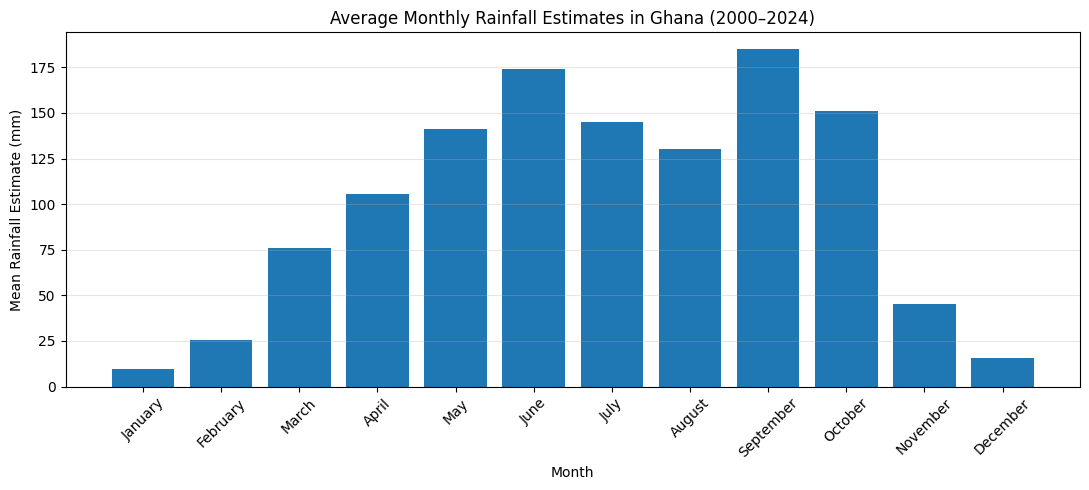

In [14]:
# Plot average rainfall by calendar month
plt.figure(figsize=(11, 5))

plt.bar(
    seasonal_rainfall["month_name"],
    seasonal_rainfall["mean_rainfall_mm"]
)

plt.title("Average Monthly Rainfall Estimates in Ghana (2000–2024)")
plt.xlabel("Month")
plt.ylabel("Mean Rainfall Estimate (mm)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Step 14: Save the monthly seasonal statistics

In [15]:
# Export monthly seasonal rainfall statistics
output_file = "ghana_monthly_rainfall_seasonality_2000_2024.csv"

seasonal_rainfall.to_csv(output_file, index=False)

print("Saved file:", output_file)
print("Months exported:", len(seasonal_rainfall))

Saved file: ghana_monthly_rainfall_seasonality_2000_2024.csv
Months exported: 12


Step 15: Download the seasonal statistics

In [16]:
# Download the monthly seasonal rainfall summary
from google.colab import files

files.download("ghana_monthly_rainfall_seasonality_2000_2024.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 16: Examine rainfall variability across years for each calendar month

In [17]:
# Calculate rainfall trends separately for each calendar month
from scipy.stats import linregress

rainfall_df["year"] = rainfall_df["time"].dt.year
rainfall_df["month"] = rainfall_df["time"].dt.month

monthly_by_year = (
    rainfall_df.groupby(["year", "month"])["precip"]
    .mean()
    .reset_index(name="mean_precip_mm")
)

monthly_trends = []

for month in range(1, 13):
    subset = monthly_by_year[monthly_by_year["month"] == month]
    result = linregress(subset["year"], subset["mean_precip_mm"])

    monthly_trends.append({
        "month": month,
        "month_name": pd.Timestamp(2000, month, 1).month_name(),
        "slope_mm_per_year": result.slope,
        "r_squared": result.rvalue ** 2,
        "p_value": result.pvalue
    })

monthly_trends_df = pd.DataFrame(monthly_trends)

display(monthly_trends_df.round(4))

,month,month_name,slope_mm_per_year,r_squared,p_value
0,1,January,-0.0695,0.0133,0.5830
1,2,February,-0.1973,0.0140,0.5731
2,3,March,0.9749,0.1345,0.0714
3,4,April,-1.2839,0.1353,0.0704
4,5,May,-0.5717,0.0380,0.3503
5,6,June,-0.1337,0.0008,0.8929
6,7,July,-0.0160,0.0000,0.9870
7,8,August,0.2944,0.0037,0.7733
8,9,September,0.7134,0.0160,0.5474
9,10,October,1.3860,0.0657,0.2161


Step 17: Visualize the monthly rainfall trends

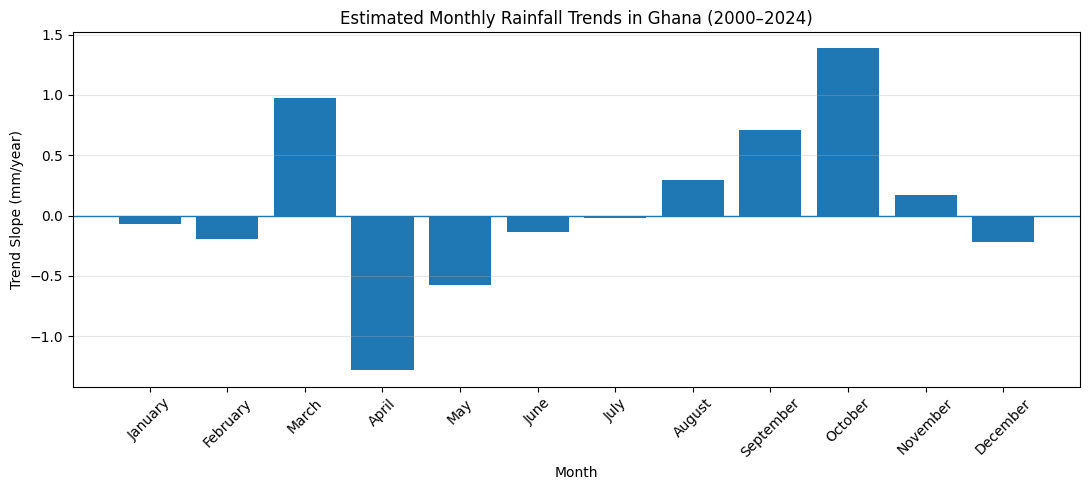

In [18]:
# Plot estimated rainfall trends by calendar month
plt.figure(figsize=(11, 5))

plt.bar(
    monthly_trends_df["month_name"],
    monthly_trends_df["slope_mm_per_year"]
)

plt.axhline(0, linewidth=1)
plt.title("Estimated Monthly Rainfall Trends in Ghana (2000–2024)")
plt.xlabel("Month")
plt.ylabel("Trend Slope (mm/year)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Step 18: Export the monthly trend results

In [19]:
# Export monthly rainfall trend results
output_file = "ghana_monthly_rainfall_trends_2000_2024.csv"

monthly_trends_df.to_csv(output_file, index=False)

print("Saved file:", output_file)
print("Monthly trends exported:", len(monthly_trends_df))

Saved file: ghana_monthly_rainfall_trends_2000_2024.csv
Monthly trends exported: 12


In [20]:
# Download monthly rainfall trend results
from google.colab import files

files.download("ghana_monthly_rainfall_trends_2000_2024.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Step 20: Save the rainfall variability summary

In [21]:
# Summarize annual rainfall variability and trend
rainfall_summary = pd.DataFrame([{
    "period": "2000–2024",
    "years": len(annual_rainfall),
    "mean_annual_rainfall_mm": annual_rainfall["annual_rainfall_mm"].mean(),
    "std_annual_rainfall_mm": annual_rainfall["annual_rainfall_mm"].std(),
    "min_annual_rainfall_mm": annual_rainfall["annual_rainfall_mm"].min(),
    "max_annual_rainfall_mm": annual_rainfall["annual_rainfall_mm"].max(),
    "coefficient_of_variation_percent": cv,
    "linear_trend_mm_per_year": trend.slope,
    "trend_r_squared": trend.rvalue ** 2,
    "trend_p_value": trend.pvalue
}])

display(rainfall_summary.round(4))

,period,years,mean_annual_rainfall_mm,std_annual_rainfall_mm,min_annual_rainfall_mm,max_annual_rainfall_mm,coefficient_of_variation_percent,linear_trend_mm_per_year,trend_r_squared,trend_p_value
0,2000–2024,25,1204.4661,125.3757,893.5364,1393.7241,10.4092,1.0527,0.0038,0.7692


Step 21: Save the summary table

In [22]:
# Export the annual rainfall summary statistics
output_file = "ghana_rainfall_variability_summary_2000_2024.csv"

rainfall_summary.to_csv(output_file, index=False)

print("Saved file:", output_file)
print("Summary records:", len(rainfall_summary))

Saved file: ghana_rainfall_variability_summary_2000_2024.csv
Summary records: 1


Step 22: Download the summary

In [23]:
# Download the rainfall variability summary
from google.colab import files

files.download("ghana_rainfall_variability_summary_2000_2024.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
# List the research output files currently available
import os

for filename in sorted(os.listdir("/content")):
    if filename.endswith(".csv"):
        print(filename)

ghana_annual_rainfall_estimates_2000_2024.csv
ghana_chirps_monthly_validated_2000_2024.csv
ghana_monthly_rainfall_seasonality_2000_2024.csv
ghana_monthly_rainfall_trends_2000_2024.csv
ghana_rainfall_variability_summary_2000_2024.csv


## Key Findings and Interpretation

This analysis examined CHIRPS rainfall data for Ghana from 2000 to 2024. The annual rainfall estimates showed year-to-year variability, with the highest estimate in 2007 (1,393.72 mm) and the lowest in 2013 (893.54 mm).

The estimated linear trend was positive (+1.05 mm per year), but it was not statistically significant (p = 0.7692; R² = 0.0038). Therefore, this analysis does not provide statistically significant evidence of a linear change in the national grid-cell-average rainfall estimate over the study period.

Monthly averages showed a seasonal pattern, with the highest mean rainfall in September (184.95 mm) and the lowest in January (9.41 mm). None of the individual monthly trend tests was statistically significant at the 5% level.

These results describe national grid-cell averages and may conceal important regional differences. The estimates use an unweighted mean of retained grid cells and should not be interpreted as area-weighted national rainfall totals. Rainfall alone also cannot establish forage availability or vegetation condition; those relationships require additional data and analysis.